# P3, Joining data
## [Please download the github repo and run locally.](https://github.com/TheCarsonWest/DSA405)

---

In this part we will be collecting the stock data that will match up with each row of the dataframe being collecting, and then joining that data with the dataframe.
## See [Assignment Quick Reference](#assignment-quick-reference) for all the rubric items

---
### Note on the data:

Since the P2 assignment, I have attempted to parse the 195 handwritten PTR reports that were published in my analysis period. 193 of them fully parsed, and they are now a part of the dataset. Almost every row that was parsed is missing crucial information, so very few of the transactions from the handwritten PTR reports make it to the final analysis.

---
## If you are doing you own analysis:
- Make sure you have run `python download_pdfs.py` to cache all the clerk directories for your analysis, and LLM-parsed them using `python ptr_pdf_to_json.py`
- This Jupyter notebook assumes all the default behavior of the previous steps, and that there a matching entry in one of the `./data/clerk_directories/` XML files for every .json file in `./data/json/`
- Run everything up to [Step 5](#part-5-actually-joining-the-stock-data-finally), this will generate your list of stock data you need to cache.
- Once `./data/scrape_dates.csv` exists, you can run `python yfinance_cache.py`. 
    - It runs at 60 requests per minute, so however many lines are in `./data/scrape_dates.csv`, thats how may seconds it will take to create `./data/scrape_dates_prices.csv`.
- After `./data/scrape_dates_prices.csv` is fully built, you can check the results of the analysis by running the rest of the cells.
---

## The data we want:
For this dataset I have decided that I want the daily high stock sprice of each transaction with each of these dates relative to the trade:
- The price of the stock on the date of purchase (`dt`)
- The price of the stock on the date of notification (`ndt`)
- The price of the stock on the date of the publishing of the PTR 
    - This is another data join that we will be doing!
- The price of the stock 45 days after the purchase
- The price of the stock today (10/20/26 will be "today")

## Creating and caching all of the stock data we need.

In order to get all of the historical stock data in the most polite way possible, we will:
- assemble our dataframe with all of our rows
- collect all of the desired stocks and all of days in which we want the daily high
- Find and remove duplicates. If we have multiple transactions that purchased the same stock on the same day, then we only need one request!
- Export to a json that we can read to build the data cache
- Use the `yfiannce` scraper package to scrape the stock data over a long period of time, building a cache of all the data we need
- Join the stock data to our dataframe to have the stock data that we want


## Step 1: Reassembling our dataframe

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd


# Edit this tuple to choose which filing years to analyze (e.g. (2023,)).
ANALYSIS_YEARS = (2023, 2024, 2025)

if not ANALYSIS_YEARS:
    raise ValueError("ANALYSIS_YEARS must contain at least one year.")

ANALYSIS_START_DATE = pd.Timestamp(
    year=min(ANALYSIS_YEARS) - 1, month=11, day=14
)
ANALYSIS_END_DATE = pd.Timestamp(
    year=max(ANALYSIS_YEARS) + 1, month=1, day=1
)

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data").is_dir()),
    Path.cwd(),
)
DATA_DIRECTORY = PROJECT_ROOT / "data"
JSON_DIRECTORY = DATA_DIRECTORY / "json"
CLERK_DIRECTORY = DATA_DIRECTORY / "clerk_directories"
json_paths = sorted(JSON_DIRECTORY.glob("*.json"))
if not json_paths:
    raise FileNotFoundError(f"No parsed JSON documents found in {JSON_DIRECTORY}")
dataframes = []

for json_path in json_paths:
    df = pd.read_json(json_path)
    df["file_name"] = json_path.name
    dataframes.append(df)

combined_df = (
    pd.concat(dataframes, ignore_index=True)
    if dataframes
    else pd.DataFrame()
)

transaction_columns = pd.json_normalize(
    combined_df["transactions"].map(
        lambda value: value if isinstance(value, dict) else {}
    ),
    sep="_"
)

parsed_df = pd.concat(
    [
        combined_df.drop(columns="transactions").reset_index(drop=True),
        transaction_columns.reset_index(drop=True),
    ],
    axis=1
)


# Making a ticker column by searching for a regex pattern between parentheses in the 'ast' column
parsed_df["ticker"] = parsed_df["ast"].str.extract(r"\((.*?)\)")[0]

# removing values in the 'ticker' column that are longer than 5 characters
parsed_df.loc[parsed_df["ticker"].str.len() > 5, "ticker"] = None
# This removes the values of 128 rows

# Fixing date columns to datetime format
for column in ["dt", "ndt"]:
    parsed_df[column] = pd.to_datetime(
        parsed_df[column],
        format="%m/%d/%Y",
        errors="coerce"
    )

# Theres apparently a lot of malformed sentinel dates that make no sense, so we will filter them out
lower_bound = ANALYSIS_START_DATE
upper_bound = ANALYSIS_END_DATE

# Classifying each row on whether or not it appeared in a handwritten PTR doc or a digital PTR doc
parsed_df["handwritten"] = parsed_df["file_name"].str.extract(r"(\d+)\.json")[0].astype(int) < 20000000


for column in ["dt", "ndt"]:
    outside_range = (
        (parsed_df[column] < lower_bound)
        | (parsed_df[column] > upper_bound)
    )
    parsed_df.loc[outside_range, column] = pd.NaT
print(parsed_df.shape)

print("Handwritten row count:")
print(parsed_df["handwritten"].sum())
print("Digital row count:")
print((~parsed_df["handwritten"]).sum())

parsed_df.head(5)

(29936, 14)
Handwritten row count:
16870
Digital row count:
13066


,file_name,own,ast,code,typ,dt,ndt,amt,cg,stat,sub,desc,ticker,handwritten
0,20000788.json,,Colgate-Palmolive Company Common Stock (CL),ST,S,2023-08-25,2023-08-25,"$1,001 - $15,000",False,New,Raymond James IRA,Tax Deferred Roll-over of IRA into TSP. Stock ...,CL,False
1,20000788.json,,"JD.com, Inc. - American Depositary Shares (JD)",ST,S,2023-08-25,2023-08-25,"$1,001 - $15,000",False,New,Raymond James IRA,Tax Deferred Roll-over of IRA into TSP. Stock ...,JD,False
2,20000807.json,,Abbott Laboratories (ABT),ST,S,2023-01-06,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,ABT,False
3,20000807.json,,Allstate Corporation (ALL),ST,S,NaT,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,ALL,False
4,20000807.json,,"AvalonBay Communities, Inc. (AVB)",ST,S,NaT,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,AVB,False


# Part 2: The bonus join to match the documents with their congressmen/women

We wanted to join this data now, so that we have the date that the document disclosing the transaction was published


### First Join (Congressmember Metadata Join)

| Dimension                                 | Specification                                                                                                                                                                                        |
| ----------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Join key(s)**                           | `DocID` (derived from `file_name` in left table; matching `DocID` in right table)                                                                                                                    |
| **Grain of the left table (`parsed_df`)** | One row per reported financial transaction within a disclosure filing                                                                                                                                |
| **Grain of the right table (`lookup`)**   | One row per PTR document filing (`DocID` deduplicated with `.drop_duplicates("DocID")`)                                                                                                              |
| **Relationship**                          | **Many-to-One (`validate="many_to_one"`)**                                                                                                                                                           |
| **Expected row count after join**         | Exactly equal to the row count of `parsed_df` before the join (29,936 rows)                                                                                                                          |
| **Join type and why**                     | **Left join (`how="left"`)**: Every transaction row stays, even if the join doesn't find matching metadata.                                                                                          |
| **What happens to unmatched rows**        | Unmatched rows retain transaction features while filling member data (`last`, `first`, `StateDst`, `pdt`) with `NaN`. <br><br>The notebook later has asssertions to ensure that this never happened. |


In [ ]:
xml_files = sorted(CLERK_DIRECTORY.glob("*FD.xml"))
if not xml_files:
    raise FileNotFoundError(f"No year FD XML files found in {CLERK_DIRECTORY}")

member_rows = []
for xml_path in xml_files:
    root = ET.parse(xml_path).getroot()
    for member in root.findall(".//Member"):
        row = {
            field: member.findtext(field, default="").strip()
            for field in (
                "Last", "First", "FilingType", "StateDst", "Year", "FilingDate", "DocID"
            )
        }
        if row["FilingType"] == "P" and row["Year"].isdigit():
            member_rows.append(row)

if not member_rows:
    raise ValueError("No PTR records found in the Clerk XML files.")
ptr_df = pd.DataFrame(member_rows)
lookup = ptr_df[["Last", "First", "StateDst", "FilingDate", "DocID", "Year"]].copy()
lookup.columns = ["last", "first", "StateDst", "pdt", "DocID", "Year"]
lookup["DocID"] = lookup["DocID"].str.strip()
lookup["pdt"] = pd.to_datetime(lookup["pdt"], format="%m/%d/%Y", errors="coerce")
lookup = lookup.drop_duplicates("DocID", keep="first")

parsed_df["DocID"] = parsed_df["file_name"].str.replace(r"\.json$", "", regex=True)
parsed_df = parsed_df.merge(
    lookup,
    on="DocID",
    how="left",
    validate="many_to_one",
).drop(columns="DocID")

if parsed_df["Year"].isna().any():
    raise ValueError("Some JSON documents do not match a PTR in the Clerk XML files.")

parsed_years = pd.to_numeric(parsed_df["Year"], errors="coerce")
parsed_df = parsed_df.loc[parsed_years.isin(ANALYSIS_YEARS)].drop(columns="Year").copy()

if parsed_df.empty:
    raise ValueError(f"No parsed PTR transactions found for years {ANALYSIS_YEARS}.")

parsed_df.head()


,file_name,own,ast,code,typ,dt,ndt,amt,cg,stat,sub,desc,ticker,handwritten,last,first,StateDst,pdt
0,20000788.json,,Colgate-Palmolive Company Common Stock (CL),ST,S,2023-08-25,2023-08-25,"$1,001 - $15,000",False,New,Raymond James IRA,Tax Deferred Roll-over of IRA into TSP. Stock ...,CL,False,Duncan,Jeff,SC03,2024-05-23
1,20000788.json,,"JD.com, Inc. - American Depositary Shares (JD)",ST,S,2023-08-25,2023-08-25,"$1,001 - $15,000",False,New,Raymond James IRA,Tax Deferred Roll-over of IRA into TSP. Stock ...,JD,False,Duncan,Jeff,SC03,2024-05-23
2,20000807.json,,Abbott Laboratories (ABT),ST,S,2023-01-06,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,ABT,False,Larsen,Rick,WA02,2023-05-26
3,20000807.json,,Allstate Corporation (ALL),ST,S,NaT,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,ALL,False,Larsen,Rick,WA02,2023-05-26
4,20000807.json,,"AvalonBay Communities, Inc. (AVB)",ST,S,NaT,2023-05-18,"$1,001 - $15,000",False,New,Richard R Larsen IRA > Ameriprise SPS Managed ...,This managed account within the RRL IRA was se...,AVB,False,Larsen,Rick,WA02,2023-05-26


#### Verfication that every row received metadata

In [3]:
# Assert that the merge was successful
assert parsed_df["last"].notna().all()
assert parsed_df["first"].notna().all()
assert parsed_df["StateDst"].notna().all()

# Part 3: Culling the data to just what we can analyze
We want to scrape and cache as little data as possible, which means we need to get rid of all of the data we cannot completely analyze, so that we don't have to scrape the values for it.

For the data to be something that we can analyze, all of the conditions must be met:

- It must have a stock/ETF ticker
    - While insider trading via an ETF is highly unlikely, I am still going to check the results for fun.
- It must have both date values
- It must be a `New` status
- While duplicate transactions within documents are plausible data, we should remove them anyways

### Note: disqualifying mislabelled documents.
On the first run of the full stack, I noticed that there were some published dates that were over a year after the purchase dates of the stocks. This is likely because the directory of documents mislabelled an initial assets report as a periodic transaction report. We will remove any rows that have a gap larger than 90 days betweem `dt` and `pdt`.

In [4]:
culled_df = parsed_df.loc[
    parsed_df["ticker"].notna()
    & parsed_df["stat"].eq("New")
    & parsed_df["dt"].notna()
    & parsed_df["ndt"].notna()
].drop_duplicates(
    subset=["file_name", "ast", "dt", "ndt", "amt"],
    keep="first",
).copy()

print(parsed_df.shape)
print(culled_df.shape)
culled_df.head()

# Remove mislabelled reports that slipped through to the list of PTR
publication_gap_days = (culled_df["pdt"] - culled_df["dt"]).abs().dt.days
culled_df = culled_df.loc[publication_gap_days.le(90)].copy()

# See how many rows were culled, grouped by 'handwritten'
culled_counts = parsed_df.shape[0] - culled_df.shape[0]
print("Total rows culled:", culled_counts)

print("rows preserved by 'handwritten':")
print(culled_df["handwritten"].value_counts())

(29936, 18)
(10666, 18)
Total rows culled: 20083
rows preserved by 'handwritten':
handwritten
False    9500
True      353
Name: count, dtype: int64


Wow, the LLM did not get to parse all of the neccesary data very often.

---

# Part 4: Generating the list of stock data we need:

With our remaining data, we will make a list of the stock tickers and dates for those stock tickers that we want to cache, and then we will use the scraping program `yfiannce_cache.py` in order to build a cache of all of the stock data.

To re-iterate, we are looking for the daily high stock price of each stock on each of these dates relative to the trade:
- The price of the stock on the date of purchase (`dt`)
- The price of the stock on the date of notification (`ndt`)
- The price of the stock on the date of the publishing of the PTR 
    - This is another data join that we will be doing!
- The price of the stock 45 days after the purchase
- The price of the stock today (10/20/26 will be "today")
 
### Note: Non-market days dates:
Because we are checking 45 days after the `dt` date, some of those days will be weekends naturally. For these dates, the scraper will not try to check the price on a weekend, but will go to the nearest previous market day.

In [5]:
today = pd.Timestamp("2026-10-20")

date_requests = pd.concat(
    [
        culled_df[["ticker", "dt"]].rename(columns={"dt": "date"}).assign(event="purchase"),
        culled_df[["ticker", "ndt"]].rename(columns={"ndt": "date"}).assign(event="notification"),
        culled_df[["ticker", "pdt"]].rename(columns={"pdt": "date"}).assign(event="PTR publication"),
        culled_df[["ticker", "dt"]]
        .assign(date=lambda df: df["dt"] + pd.Timedelta(days=45))
        [["ticker", "date"]]
        .assign(event="45 days after purchase"),
        culled_df[["ticker"]].assign(date=today, event="today"),
    ],
    ignore_index=True,
)

date_requests["date"] = pd.to_datetime(date_requests["date"]).dt.normalize()
date_requests = date_requests.dropna(subset=["ticker", "date"])

# Unique ticker/date pairs to fetch; date_requests retains the event labels.
scrape_dates = (
    date_requests[["ticker", "date"]]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)
print("scrape dates before dropping duplicates")
pre_dropped_len = len(scrape_dates)
print(pre_dropped_len)
scrape_dates = scrape_dates.drop_duplicates()

print(f"Unique ticker/date pairs: {len(scrape_dates):,}")
print(f"Dropped {pre_dropped_len - len(scrape_dates):,} duplicate rows")

# This is the request list; yfiannce_cache.py writes prices to a separate file.
scrape_dates.to_csv(DATA_DIRECTORY / "scrape_dates.csv", index=False)



scrape dates before dropping duplicates
49265
Unique ticker/date pairs: 33,803
Dropped 15,462 duplicate rows


# Part 5: Actually Joining the stock data 

### If you are using this pipeline for yourself, go run `python yfinance_cache.py` before continuing

---

### Example test run of `yfinance_cache.py`

In [20]:
import sys
import tempfile
import time
from pathlib import Path

# Add the parent directory to sys.path so yfinance_cache.py can be imported
base_dir = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
module_dir = base_dir if (base_dir / "yfinance_cache.py").exists() else base_dir.parent
sys.path.insert(0, str(module_dir))

import yfinance_cache


example_csv = """ticker,date
AAPL,2023-06-01
AAPL,2023-10-02
AAPL,2024-09-03
FakeTicker,2023-03-01
NVDA,2023-02-15
NVDA,2026-02-16
"""

# Pre-populated with a made-up value to demonstrate skipping cached entries
finished_csv = """ticker,date,price
AAPL,2023-06-01,999.9999
"""


def main() -> None:
    global finished_csv

    with tempfile.TemporaryDirectory() as tmp_dir:
        tmp_path = Path(tmp_dir)
        yfinance_cache.INPUT_PATH = tmp_path / "scrape_dates.csv"
        yfinance_cache.OUTPUT_PATH = tmp_path / "scrape_dates_prices.csv"

        yfinance_cache.INPUT_PATH.write_text(example_csv, encoding="utf-8")
        yfinance_cache.OUTPUT_PATH.write_text(finished_csv, encoding="utf-8")

        requests_to_fetch = yfinance_cache.load_requests()
        cached_prices = yfinance_cache.load_cached_prices()
        yfinance_cache.write_cache(cached_prices)

        print(f"Starting scrape for {len(requests_to_fetch):,} unique ticker/date pairs.\n")
        for index, (ticker, date) in enumerate(requests_to_fetch, start=1):
            key = (ticker, date)
            current_price = cached_prices.get(key, "")
            if current_price:
                print(
                    f"[{index}/{len(requests_to_fetch)}] Skipping {ticker} on {date} "
                    f"(already cached: {current_price})"
                )
                continue

            print(
                f"[{index}/{len(requests_to_fetch)}] Fetching High for {ticker} on {date}...",
                end=" ",
            )
            price, actual_date = yfinance_cache.fetch_high_price(ticker, date)
            cached_prices[key] = price
            yfinance_cache.append_cache_entry(ticker, date, price)

            if price == "NaN":
                print("No price cached.")
            elif actual_date != date:
                print(f"Success: {price} (used previous market date: {actual_date})")
            else:
                print(f"Success: {price}")

            time.sleep(yfinance_cache.SLEEP_TIME)

        yfinance_cache.write_cache(cached_prices)
        finished_csv = yfinance_cache.OUTPUT_PATH.read_text(encoding="utf-8")

    print("\nScraping complete. Final finished_csv:\n")
    print(finished_csv)


if __name__ == "__main__":
    main()

Crumb fetch rate-limited (HTTP 429), continuing without crumb


Starting scrape for 6 unique ticker/date pairs.

[1/6] Skipping AAPL on 2023-06-01 (already cached: 999.9999)
[2/6] Fetching High for AAPL on 2023-10-02... Success: 171.8435
[3/6] Fetching High for AAPL on 2024-09-03... Success: 226.9278
[4/6] Fetching High for FakeTicker on 2023-03-01... 
   Attempt 1/3 failed: 401 Client Error: Unauthorized for url: https://query2.finance.yahoo.com/v10/finance/quoteSummary/FAKETICKER?modules=financialData%2CquoteType%2CdefaultKeyStatistics%2CassetProfile%2CsummaryDetail&corsDomain=finance.yahoo.com&formatted=false&symbol=FAKETICKER&lang=en-US&region=US 
   Attempt 2/3 failed: 401 Client Error: Unauthorized for url: https://query2.finance.yahoo.com/v10/finance/quoteSummary/FAKETICKER?modules=financialData%2CquoteType%2CdefaultKeyStatistics%2CassetProfile%2CsummaryDetail&corsDomain=finance.yahoo.com&formatted=false&symbol=FAKETICKER&lang=en-US&region=US 

$FAKETICKER: possibly delisted; no timezone found


No data (invalid ticker or no historical price) -> NaN
No price cached.
[5/6] Fetching High for NVDA on 2023-02-15... Success: 22.7788
[6/6] Fetching High for NVDA on 2026-02-16... Success: 187.0623 (used previous market date: 2026-02-13)

Scraping complete. Final finished_csv:

ticker,date,price
AAPL,2023-06-01,999.9999
AAPL,2023-10-02,171.8435
AAPL,2024-09-03,226.9278
FakeTicker,2023-03-01,NaN
NVDA,2023-02-15,22.7788
NVDA,2026-02-16,187.0623




Ok, after about 10 hours of scraping and caching all of the data that `yfinance` could manage (Across 1569 unique tickers, 206 of them had dates with no returned price high), it is time to construct the dataframe for the stock data and join it to the transaction data.


The ticker-date request list is saved in `scrape_dates.csv`; `yfiannce_cache.py` reads it and stores cached prices separately in `scrape_dates_prices.csv`.

- [scrape_dates.csv](./../data/scrape_dates.csv)
- [scrape_dates_prices.csv](./../data/scrape_dates_prices.csv)
- [yfinance_cache.py](./../yfiannce_cache.py)


### Second Join (Price Data Lookup)

| Dimension                             | Specification                                                                                                                                      |
| ------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Join key(s)**                       | Composite key: `[ticker, date]` (where date corresponds to `dt`, `ndt`, `pdt`, `dt_plus_45`, or `today`)                                           |
| **Grain of left table (`culled_df`)** | One row per validated stock transaction                                                                                                            |
| **Grain of right table (`prices`)**   | One row per unique `[ticker, date]` market observation                                                                                             |
| **Relationship**                      | Many-to-One lookup                                                                                                                                 |
| **Expected row count after join**     | Exactly equal to `len(culled_df)` before alignment (9,853 rows)                                                                                    |
| **Join type and why**                 | Left positional lookup (`reindex` over a MultiIndex) to align market quotes onto transactions without mutating table structure or reordering rows. |
| **What happens to unmatched rows**    | Returns `NaN` (e.g., delisted stocks or tickers missing historical coverage).                                                                      |


In [6]:
prices = pd.read_csv(DATA_DIRECTORY / "scrape_dates_prices.csv", dtype={"ticker": str})
prices["date"] = pd.to_datetime(prices["date"], errors="coerce").dt.normalize()

# Require one price per ticker/date so lookups cannot be ambiguous.
assert not prices.duplicated(["ticker", "date"]).any(), "Duplicate ticker/date rows in price data"

price_lookup = prices.set_index(["ticker", "date"])["price"]
row_count_before = len(culled_df)

price_dates = {
    "dt": culled_df["dt"],
    "ndt": culled_df["ndt"],
    "pdt": culled_df["pdt"],
    "today": pd.Series(today, index=culled_df.index),
    "dt_plus_45": culled_df["dt"] + pd.Timedelta(days=45),
}

for label, dates in price_dates.items():
    keys = pd.MultiIndex.from_arrays(
        [culled_df["ticker"], pd.to_datetime(dates).dt.normalize()]
    )
    culled_df[f"high_{label}"] = price_lookup.reindex(keys).to_numpy()

assert len(culled_df) == row_count_before, "The join changed the number of rows"

In [7]:
culled_df.head(10)

,file_name,own,ast,code,typ,dt,ndt,amt,cg,stat,...,handwritten,last,first,StateDst,pdt,high_dt,high_ndt,high_pdt,high_today,high_dt_plus_45
15,20000807.json,,General Dynamics Corporation (GD),ST,P,2023-04-05,2023-05-18,"$1,001 - $15,000",False,New,...,False,Larsen,Rick,WA02,2023-05-26,213.8121,197.2965,193.1306,346.85,197.5388
35,20016861.json,SP,UnitedHealth Group Incorporated Common Stock (...,ST,P,2025-04-10,2025-05-15,"$1,001 - $15,000",False,New,...,False,McGuire,John,VA05,2025-05-16,578.4871,265.8976,283.0442,422.40,288.0517
36,20018054.json,,Alphabet Inc. - Class C Capital Stock (GOOG),ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,192.0749,193.3673,196.4692,341.00,187.0543
37,20018054.json,,"Amazon.com, Inc. - Common Stock (AMZN)",ST,P,2025-01-02,2025-01-05,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,225.1500,225.3600,221.7100,265.34,229.8900
38,20018054.json,,"Amazon.com, Inc. - Common Stock (AMZN)",ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,225.1500,225.3600,221.7100,265.34,229.8900
39,20018054.json,,Amphenol Corporation Common Stock (APH),ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,34.7805,34.6916,35.0520,80.79,34.5929
40,20018054.json,,Apple Inc. - Common Stock (AAPL),ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,247.3053,242.4208,238.4297,343.06,244.0489
41,20018054.json,,"Arista Networks, Inc. Common Stock (ANET)",ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,114.1500,115.4800,116.0800,183.33,109.0500
42,20018054.json,,AT&T Inc. (T),ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,21.1666,20.9748,20.3899,23.68,23.9887
43,20018054.json,,"BlackRock, Inc. Common Stock (BLK)",ST,P,2025-01-02,2025-01-03,"$1,001 - $15,000",False,New,...,False,Comer,James,KY01,2025-01-10,995.0265,987.2176,946.7745,1150.21,943.4965



`head` by chance shows us that sadly, delisted stocks do not appear to have been parsed (ATVI was bought by Microsoft in 2023)

---

Now we need to cull more data, drop the rows that do not have any price data.

In [8]:
print(f"Number of rows before filtering: {len(culled_df)}")

price_columns = [f"high_{label}" for label in price_dates]
culled_df = culled_df.loc[culled_df[price_columns].notna().sum(axis=1) >= 2].copy()

print(f"Number of rows after filtering: {len(culled_df)}")

Number of rows before filtering: 9853
Number of rows after filtering: 9214


# Analysis: 
Lets look at who has the best *luck* between when they purchase/sell a stock and when they report their transaction:

In [9]:
# Measure the price change from the transaction date to PTR publication.
transactions = culled_df.copy()
transactions["high_dt"] = pd.to_numeric(transactions["high_dt"], errors="coerce")
transactions["high_pdt"] = pd.to_numeric(transactions["high_pdt"], errors="coerce")
transactions["change_pct"] = (
    (transactions["high_pdt"] - transactions["high_dt"])
    / transactions["high_dt"]
    * 100
)

# A positive score means a favorable move: up for buys, down for sells.
action = transactions["typ"].fillna("").str.strip().str.upper()
valid_prices = (
    transactions["high_dt"].gt(0)
    & transactions["high_pdt"].notna()
)

buys = transactions.loc[valid_prices & action.str.startswith("P")].copy()
buys["luck_score_pct"] = buys["change_pct"]

sells = transactions.loc[valid_prices & action.str.startswith("S")].copy()
sells["luck_score_pct"] = -sells["change_pct"]

display_columns = [
    "first", "last", "ticker", "typ", "dt", "pdt",
    "high_dt", "high_pdt", "change_pct", "amt", "file_name",
]

luckiest_buys = buys.nlargest(10, "luck_score_pct")[display_columns]
luckiest_sells = sells.nlargest(10, "luck_score_pct")[display_columns]

print("Luckiest buys (largest price increases):")
display(luckiest_buys)

print("Luckiest sells (largest price decreases):")
display(luckiest_sells)

Luckiest buys (largest price increases):


,first,last,ticker,typ,dt,pdt,high_dt,high_pdt,change_pct,amt,file_name
7026,Julie,Johnson,PLTR,P,2025-01-15,2025-02-12,68.8500,117.5900,70.791576,"$1,001 - $15,000",20026762.json
10020,Tim,Moore,TQQQ,P,2025-04-22,2025-06-13,22.7340,37.0280,62.874989,"$15,001 - $50,000",20030522.json
10021,Tim,Moore,TQQQ,P,2025-04-17,2025-06-13,22.8872,37.0280,61.784753,"$15,001 - $50,000",20030522.json
6979,James,Comer,PLTR,P,2025-01-21,2025-02-11,73.6360,118.6600,61.144006,"$1,001 - $15,000",20026750.json
1723,Daniel,Goldman,OPEN,P,2023-04-10,2023-05-19,1.6900,2.5250,49.408284,"$1,001 - $15,000",20022948.json
9406,Jefferson,Shreve,COIN,P,2025-05-08,2025-06-22,210.4700,310.7500,47.645745,"$15,001 - $50,000",20030387.json
6855,Gilbert,Cisneros,PLTR,P,2025-01-24,2025-02-11,82.2400,118.6600,44.285019,"$1,001 - $15,000",20026726.json
2341,Josh,Gottheimer,NVDA,P,2023-05-04,2023-06-11,27.7709,39.5895,42.557497,"$1,001 - $15,000",20023087.json
12074,Gilbert,Cisneros,SMCI,P,2025-09-05,2025-10-10,41.1800,58.5100,42.083536,"$1,001 - $15,000",20032248.json
8362,Jefferson,Shreve,APP,P,2025-04-07,2025-05-08,253.6100,357.6400,41.019676,"$15,001 - $50,000",20030231.json


Luckiest sells (largest price decreases):


,first,last,ticker,typ,dt,pdt,high_dt,high_pdt,change_pct,amt,file_name
7777,Jefferson,Shreve,PCVX,S,2025-03-05,2025-04-11,74.1000,31.3100,-57.746289,"$15,001 - $50,000",20029038.json
1331,Daniel,Goldman,WAL,S,2023-03-06,2023-04-17,70.7797,30.4380,-56.996144,"$1,001 - $15,000",20022653.json
8856,Dan,Newhouse,UNH,S (partial),2025-04-11,2025-05-16,582.7929,283.0442,-51.433142,"$1,001 - $15,000",20030292.json
2712,Josh,Gottheimer,ADYEY,S (partial),2023-07-19,2023-08-21,17.5120,9.0700,-48.206944,"$1,001 - $15,000",20023500.json
2713,Josh,Gottheimer,ADYEY,S (partial),2023-07-18,2023-08-21,17.4600,9.0700,-48.052692,"$1,001 - $15,000",20023500.json
7314,Rob,Bresnahan,TTD,S,2025-02-10,2025-03-07,125.8000,67.2000,-46.581876,"$1,001 - $15,000",20027923.json
3569,Virginia,Foxx,USDP,S,2023-11-10,2023-12-05,0.3999,0.2235,-44.111028,"$1,001 - $15,000",20024072.json
3101,Josh,Gottheimer,ARQT,S,2023-09-15,2023-10-15,7.1700,4.0700,-43.235704,"$1,001 - $15,000",20023833.json
7744,Jefferson,Shreve,MRVL,S,2025-03-05,2025-04-11,90.3506,53.2213,-41.094691,"$15,001 - $50,000",20029038.json
3964,Rob,Bresnahan,ELF,S,2025-01-13,2025-02-13,132.3900,78.2900,-40.864114,"$1,001 - $15,000",20024346.json


# Assignment Quick Reference
## 1. Acquisition code
### Scraping and caching was delegated to [yfinance_cache.py](./../yfiannce_cache.py)
`yfinance` uses the public Yahoo Finance API to get daily highs. [See the API return for NVDA](https://query2.finance.yahoo.com/v8/finance/chart/NVDA) (I'm glad I could delegate handling this API to an external package, its a pretty complex json response)

- ✅ Rate limited. One request per second unless the source documents otherwise.
	- 60 Requests per minute was used
```py
REQUESTS_PER_MINUTE = 60
SLEEP_TIME = 60.0 / REQUESTS_PER_MINUTE
```
- ✅ Honest User-Agent identifying the request as coursework
	- Identified myself as student coursework to the server
	```py
	session.headers["User-Agent"] = ("DSA405-student-coursework (NC State; teaching exercise)")
	```
- ✅ Cached. Never fetch the same resource twice in one run. Save the raw response to disk and read from there on re-runs.
	- Requested ticker/date pairs are in `data/scrape_dates.csv`; cached prices are written to `data/scrape_dates_prices.csv`.
	- Failed requests are cached as `NaN`; use `--retry-failed` to retry them.
- ✅ Handles pagination, if there is any.
	- No pagination
- ✅ Handles the problems real websites cause: timeouts, non-200 responses, and selectors that match nothing (a selector is the pattern your code uses to find an element in a page).
	- Transient failures are attempted 3 times before `NaN` is cached.
- ✅ Fails loudly. "Fails loudly" means the code stops with an error message instead of continuing and producing wrong output with no message. Raise an error, or log a warning, on any condition that would otherwise produce wrong output silently.
	- Empty results and exhausted retries are stored as `NaN` and are not requested again by default.
    - (For the join with the documents directory) Assertions were in place that every row got its personally identifying information from the matching document. It would have stopped had any rows not receieved their join.

## 2. Ethics and legality in practice
- The data aquisition matches the plan in A8 exactly (plus some extra data)
- The final version is the same as the plan, except that we ended up pulling slightly more data than I initially outlined. For each row there are two more dates and prices: the date/price 45 days after purchase, and the date/price on the publishing of the PTR document.
- Once again, no logins or paywalls were bypassed. No protections were circumvented. There is 'personal information', but it is personal information about public officials who are required by law to share it with the public.

## 3. Join Design

This project executes two distinct joins:
1. **Metadata Join:** Joining parsed transactions with House Clerk PTR filing directory data ([Part 2](#part-2-the-bonus-join-to-match-the-documents-with-their-congressmenwomen)) so that every row has metadata on the congress member who filed it (including the date the document was published).
2. **Market Price Join:** Joining the culled trade records with scraped historical daily price highs ([Part 5](#part-5-actually-joining-the-stock-data-finally)).




* The failure this join protects against is a **fanout**: 
	*  It protects against fanouts with pandas' internal join validation (`validate="many_to_one"`) in [Cell 13](#part-2-the-bonus-join-to-match-the-documents-with-their-congressmenwomen). In Part 5, `assert not prices.duplicated(["ticker", "date"]).any()` guarantees that no duplicate keys exist in the price lookup index. 

## 4. Verification Suite:
We use assertions to make sure nothing has broken in 3 seperate places:
- First Join ([Part 2 Cell 3](#verfication-that-every-row-received-metadata)): making sure every row got metadata on the congressmember who published the document that the transaction came from.
- Second Join ([Part 5 Cell 6](#part-5-actually-joining-the-stock-data-finally), assertion near the beginning): Making sure none of the right dataframe (the price data) had duplicate key. no 2 rows had the same ticker and date. 
- Second Join ([Part 5 Cell 6](#part-5-actually-joining-the-stock-data-finally), final line): Making sure we didn't lose or gain any rows in the join with the price data, because that should be impossible 

## 5. What Suprised Me:

I started this assignemnt once I finished parsing the handwritten PTR reports, so loading them in to this notebook was the first time that I saw that **there are more transactions in the 193 parsed handwritten PTR reports than there are in the 1229 parsed digital PTR reports!**. There are 16,870 transaction rows in the handwritten section of the data, and 13,066 rows in the digital section. Unfortunately, the janky formatting of these handwritten documents was too much for the LLM to figure out, and 97.9% of them were culled for not having enough data. If the congressmembers who submitted handwritten documents did so to hide their insider trading, they certainly beat me. A much more complex computer vision program would likely have to be written to actually parse them, and that is beyond the scope of what I plan on doing for this class.



## Self-graded rubric

| Criterion                     | Self Grade | The short version                                                                       |
| ----------------------------- | ---------- | --------------------------------------------------------------------------------------- |
| Acquisition code              | 4/4        | Retrieves reliably, rate-limited, cached, and fails loudly, with one demonstrated catch. Reproduced small scale sample of `yfinance_cache.py` for viewing at [Step 5](#example-test-run-of-yfinance_cachepy) |
| Ethics & legality in practice | 4/4        | Matches the A8 plan; drift documented. Removed personal comment (my apologies, this was very unprofessional of me)                                                   |
| Join design                   | 4/4        | Keys and cardinality stated **before** the merge; alternatives ruled out, built-in assertions and later assertions to ensure no fan-out or no missing values for columns that shouldn't have missing values                |
| **Verification suite**        | 3/4        | three or more assertions                                                                |
| Reproducibility & readability | 4/4        | README much more up to date, code should be able to be run by anyone, for any date range, if they so please.                                 |


## Current state of the cleaning log

| #      | Target Column / Scope          | Change Made                                                                                                     | Rows / Cells Affected                          | Why                                                                                                                                                          | What is Lost                                                                                                  |
| :----- | :----------------------------- | :-------------------------------------------------------------------------------------------------------------- | :--------------------------------------------- | :----------------------------------------------------------------------------------------------------------------------------------------------------------- | :------------------------------------------------------------------------------------------------------------ |
| **1**  | `ticker`                       | Replaced ticker strings longer than 5 characters with `None`                                                    | **233 cells**                                  | Tickers cannot be longer than 5 characters                                                                                                                   | 233 false-positive ticker strings misidentified during regex extraction.                                      |
| **2**  | `dt`                           | Coerced raw text strings into `datetime64[ns]` with `errors="coerce"`                                           | **11,307 cells**                               | Converts text dates (`MM/DD/YYYY`) into proper timestamps required for chronological ordering, range checks, and joins.                                      | 11,307 unparseable entries (mostly unparsed/handwritten lines, empty fields, or corrupted text) set to `NaT`. |
| **3**  | `ndt`                          | Coerced raw text strings into `datetime64[ns]` with `errors="coerce"`                                           | **9,503 cells**                                | Converts notification date text into standardized timestamps to measure reporting delays.                                                                    | 9,503 malformed strings or empty values set to `NaT`.                                                         |
| **4**  | `dt`                           | Replaced dates outside the study bounds (`< 2022-11-14` or `> 2026-01-01`) with `NaT`                           | **372 cells**                                  | Eliminates impossible dates, OCR digit flips (e.g., years in the 1900s or 2090s), and LLM hallucinations.                                                    | 372 invalid date values reset to `NaT`.                                                                       |
| **5**  | `ndt`                          | Replaced notification dates outside the study bounds with `NaT`                                                 | **413 cells**                                  | Eliminates impossible notification dates and future dates that contradict the filing timeline.                                                               | 413 invalid notification date values reset to `NaT`.                                                          |
| **6**  | Lookup table (`DocID`)         | Deduplicated lookup table on `DocID` prior to metadata merge                                                    | **0 rows** *(already unique)*                  | Guarantees a strict Many-to-One cardinality to satisfy `validate="many_to_one"` and prevent fanout duplication.                                              | None (all 1,422 PTR documents were uniquely indexed).                                                         |
| **7**  | Full DataFrame                 | Filtered out rows missing required trade metadata (`ticker.notna() & stat == 'New' & dt.notna() & ndt.notna()`) | **18,560 rows dropped** <br>*(leaving 11,376)* | Transactions lacking tickers, dates, or non-new status cannot be analyzed in a meaningful way                                                                | 18,560 unanalyzable rows.                                                                                     |
| **8**  | Full DataFrame                 | Dropped identical intra-document duplicate transactions (`file_name`, `ast`, `dt`, `ndt`, `amt`)                | **710 rows dropped** <br>*(leaving 10,666)*    | OCR and document parsers frequently extract redundant transaction line items when files span page breaks.                                                    | 710 redundant duplicate transaction records within filings.                                                   |
| **9**  | Full DataFrame (`pdt` vs `dt`) | Filtered out rows where disclosure publication gap exceeded 90 days (`\|pdt - dt\| > 90`)                       | **813 rows dropped** <br>*(leaving 9,853)*     | Periodic Transaction Reports are legally mandated within 30–45 days. Gaps > 90 days indicate mislabelled Annual Financial Disclosures rather than true PTRs. | 813 non-periodic or misclassified asset disclosure rows.                                                      |
| **10** | Market Prices (`high_*`)       | Dropped rows with fewer than 2 valid market price observations across reference dates                           | **639 rows dropped** <br>*(leaving 9,214)*     | We want to measure the performance of a trade, if we only have 1 date, then we have nothing to compare at all.                                               | 639 transactions that only one daily high could be found for the 5 different price dates                      |




# Bonus: Graphs & Stats generated for the lightning talk:

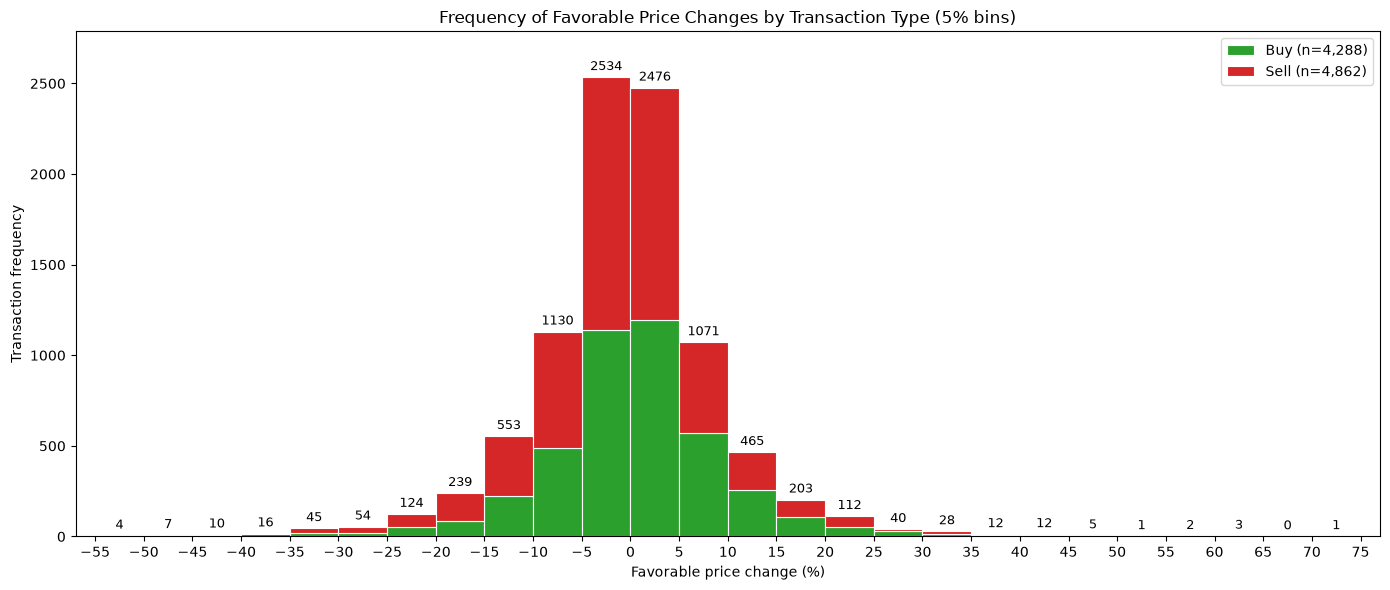

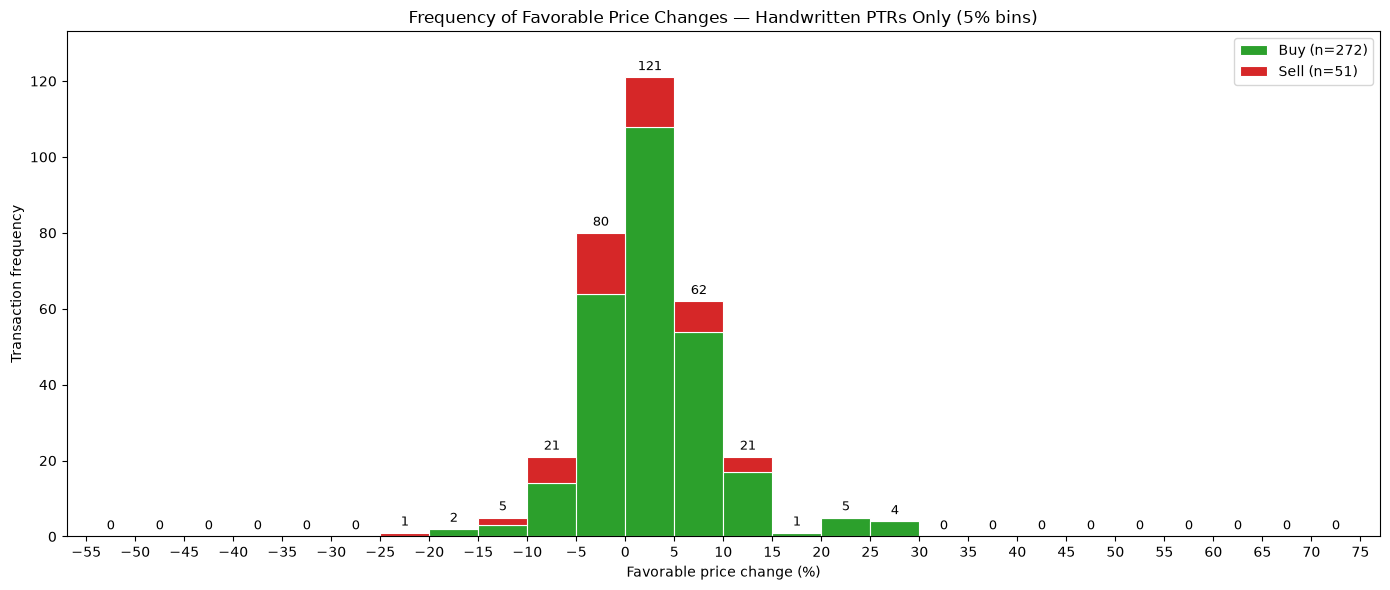

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare transaction data with favorable price change and buy/sell flags
hist_df = transactions.copy()
hist_df["action"] = hist_df["typ"].fillna("").str.strip().str.upper()
hist_df["change_pct"] = pd.to_numeric(hist_df["change_pct"], errors="coerce")

is_buy = hist_df["action"].str.startswith("P")
is_sell = hist_df["action"].str.startswith("S")

hist_df = hist_df.loc[
    (is_buy | is_sell)
    & hist_df["high_dt"].gt(0)
    & hist_df["high_pdt"].notna()
    & np.isfinite(hist_df["change_pct"])
].copy()

hist_df["is_buy"] = hist_df["action"].str.startswith("P")
hist_df["luck_score_pct"] = np.where(
    hist_df["is_buy"],
    hist_df["change_pct"],
    -hist_df["change_pct"],
)

# 5% bins covering the full dataset range (aligned to multiples of 5)
bin_min = int(np.floor(hist_df["luck_score_pct"].min() / 5) * 5+35)
bin_max = int(np.ceil(hist_df["luck_score_pct"].max() / 5) * 5)
bins = np.arange(bin_min, bin_max + 5, 5)


def plot_buy_sell_histogram(df, bins, title):
    buy_vals = df.loc[df["is_buy"], "luck_score_pct"].to_numpy()
    sell_vals = df.loc[~df["is_buy"], "luck_score_pct"].to_numpy()

    buy_counts, _ = np.histogram(buy_vals, bins=bins)
    sell_counts, _ = np.histogram(sell_vals, bins=bins)
    total_counts = buy_counts + sell_counts

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.hist(
        [buy_vals, sell_vals],
        bins=bins,
        stacked=True,
        color=["#2ca02c", "#d62728"],  # green for buys, red for sells
        edgecolor="white",
        linewidth=0.8,
        label=[f"Buy (n={len(buy_vals):,})", f"Sell (n={len(sell_vals):,})"],
    )

    # Add total count labels on top of each bar
    bin_centers = (bins[:-1] + bins[1:]) / 2
    for x, count in zip(bin_centers, total_counts):
        ax.annotate(
            f"{count}",
            xy=(x, count),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    max_count = total_counts.max() if len(total_counts) else 0
    ax.set_ylim(0, max(max_count * 1.10, 1))
    ax.set_xticks(bins)
    ax.set_xlim(bins[0] - 2, bins[-1] + 2)
    ax.set_xlabel("Favorable price change (%)")
    ax.set_ylabel("Transaction frequency")
    ax.set_title(title)
    ax.legend()

    fig.tight_layout()
    plt.show()


# 1. All transactions
plot_buy_sell_histogram(
    hist_df,
    bins=bins,
    title="Frequency of Favorable Price Changes by Transaction Type (5% bins)",
)

# 2. Handwritten == True transactions only
handwritten_hist_df = hist_df.loc[hist_df["handwritten"]].copy()
plot_buy_sell_histogram(
    handwritten_hist_df,
    bins=bins,
    title="Frequency of Favorable Price Changes — Handwritten PTRs Only (5% bins)",
)

In [11]:
handwritten_end_count = culled_df["handwritten"].sum()

print(f"Handwritten transactions that made it to the end: {handwritten_end_count:,}")
print(f"Total transactions at the end: {len(culled_df):,}")
print(
    f"Share handwritten: "
    f"{handwritten_end_count / len(culled_df):.2%}"
)

Handwritten transactions that made it to the end: 324
Total transactions at the end: 9,214
Share handwritten: 3.52%


In [12]:
average_comparison = pd.Series(
    {
        "All transactions": hist_df["luck_score_pct"].mean(),
        "Handwritten PTR transactions": hist_df.loc[
            hist_df["handwritten"], "luck_score_pct"
        ].mean(),
    },
    name="Average favorable change (%)",
)

average_comparison.to_frame()

,Average favorable change (%)
All transactions,-0.446643
Handwritten PTR transactions,2.494906


In [13]:
def canonicalize_amt(series: pd.Series) -> pd.Series:
    """Parse PTR amount strings into integer dollar amounts (minimum for binned ranges)."""
    cleaned = series.astype("string").str.strip()

    # Extract the first dollar amount (handles ranges like "$1,001 - $15,000" and "Over $1,000,000")
    extracted = (
        cleaned.str.extract(
            r"(?i)^(?:over\s+)?\$?\s*([\d,]+(?:\.\d+)?)",
            expand=False,
        )
        .str.replace(",", "", regex=False)
    )

    numeric = pd.to_numeric(extracted, errors="coerce")

    # Optional: treat "Over $1,000,000" as 1,000,001 instead of 1,000,000
    # is_over = cleaned.str.match(r"(?i)^over\b", na=False)
    # numeric = numeric.where(~is_over, numeric + 1)

    return numeric.round().astype("Int64")


culled_df["amt_int"] = canonicalize_amt(culled_df["amt"])

# Verify nothing valid failed to parse
unparsed = culled_df.loc[culled_df["amt"].notna() & culled_df["amt_int"].isna(), "amt"]
assert unparsed.empty, f"Failed to parse amt values: {unparsed.unique()}"

# Preview the mapping across all unique raw values
(
    culled_df[["amt", "amt_int"]]
    .value_counts(dropna=False)
    .reset_index(name="count")
)

,amt,amt_int,count
0,"$1,001 - $15,000",1001,7128
1,"$15,001 - $50,000",15001,1370
2,"$50,001 - $100,000",50001,324
3,"$100,001 - $250,000",100001,160
4,"$1,001-$15,000",1001,61
5,"$250,001 - $500,000",250001,43
6,"$500,001 - $1,000,000",500001,29
7,"$1,000-$15,000",1000,26
8,"$1,000,001 - $5,000,000",1000001,25
9,"$15,001-$50,000",15001,13
